# clock/15 — order under *dependencies*

The multiclock corpus (`condition_data` / `multiline_prompts`) has mutually **independent** steps:
every order is correct, so the only thing that can govern the order is the prompt — and `16` shows
it does. This notebook adds real dependencies between steps and asks the two questions the
independent corpus cannot.

1. **Behavioural** — with a dependency present, does the LM still follow the prompt's listing order,
   or does it reorder to satisfy the graph?
2. **Causal** — does the move-on signal still advance when the next step's dependencies are
   **unmet**?

*(The previous contents of this notebook — the 21 hand-written task-level order situations — are at
commit `7ed4339`. They established the baseline this builds on: with no dependency the model follows
the listing, blindly enough to change the answer; with a derived dependency it reorders.)*

### Corpus design (`src/goals/dependency_data.py`)

**Every edge is referential.** A step's text names the producing variable (`divs has more than 5
elements`), so a violation is a `NameError` and is detectable by parsing. The tempting alternative —
`a = the third smallest divisor of n` next to `b = the list of all divisors` — is **not a
dependency**: `a` is fully specified in terms of `n`, nothing obliges the model to use `b`, and an
inline implementation is correct. That would measure whether the model chooses to *reuse* an
intermediate.

**One value-producing step, boolean consumers.** Same stub, one variable per step, same aggregating
print, same instruction shape as the multiclock corpus — so the move-on vector stays in
distribution and a null result in §3 is attributable to the dependency, not to a change of domain.

**Templates, not fixed strings**, so ~10 graphs expand into hundreds of instances.

### Measuring order

Two numbers, because "followed the dependency" and "followed the prompt" are not opposites:

* **violation rate** over the DAG's *edges* — was any consumer written before its producer?
* **listing adherence on the FREE pairs** — Kendall τ against the prompt order, restricted to pairs
  the DAG leaves **incomparable**. This is the real question: where the dependency does not
  constrain, does prompt order still govern?

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging, itertools
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.markup import escape
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print(f"n_layer={mt.n_layer}  n_heads={mt.model.config.num_attention_heads}")

2026-08-10 17:54:15 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

n_layer=64  n_heads=40


In [3]:
# ── §1: the graphs ─────────────────────────────────────────────────────────
from src.goals.dependency_data import (GRAPHS, GRAPHS_BY_NAME, DepGraph, DepStep,
                                       is_valid_order, violations, constrained_pairs,
                                       free_pairs, topological_orders)

t = Table(title=f"{len(GRAPHS)} dependency graphs")
for c in ["graph", "steps", "edges", "valid orders", "free pairs", "pivotable", "shape"]:
    t.add_column(c, justify="left" if c in ("graph", "pivotable", "shape") else "right")
for g in GRAPHS:
    n_ord = len(topological_orders(g, limit=500))
    fp = len(free_pairs(g))
    shape = ("forced chain" if fp == 0 else "fork" if n_ord >= 6 else "diamond/chain")
    t.add_row(g.name, str(len(g.steps)), str(len(g.edges())), str(n_ord), str(fp),
              ", ".join(g.pivotable()), shape)
rich_print(t)
rich_print("[grey58]`free pairs` is where prompt order is still allowed to govern — a graph with 0 "
           "of them (deep_chain) is fully forced and can only show violations, never adherence."
           "[/grey58]")

def show_graph(g, params=None, rng=None):
    params = params if params is not None else g.sample_params(rng or random.Random(0))
    gt = Table(title=f"[bold]{g.name}[/bold]  ·  params={params}", box=SIMPLE_HEAVY,
               expand=True, pad_edge=False, title_justify="left")
    for c in ["var", "requires", "specification", "implementation"]:
        gt.add_column(c, overflow="fold")
    for s in g.steps:
        sty = "bold cyan" if not s.requires else "white"
        gt.add_row(Text(s.var, style=sty), Text(", ".join(s.requires) or "—", style="grey58"),
                   Text(s.render_text(params)), Text(s.render_single(params).strip(), style="grey58"))
    rich_print(gt)
    rich_print(f"   edges (consumer -> producer): {g.edges()}")
    rich_print(f"   valid orders: {topological_orders(g)[:3]}{' …' if len(topological_orders(g)) > 3 else ''}")
    rich_print(f"   free pairs  : {[sorted(x) for x in free_pairs(g)] or '—'}\n")

for name in ("divs_fork", "divs_diamond", "two_producers", "deep_chain"):
    show_graph(GRAPHS_BY_NAME[name], rng=random.Random(0))

                                    11 dependency graphs                                     
┏━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ graph          ┃ steps ┃ edges ┃ valid orders ┃ free pairs ┃ pivotable    ┃ shape         ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ divs_fork      │     4 │     3 │            6 │          3 │ divs         │ fork          │
│ divs_chain     │     4 │     3 │            2 │          1 │ divs, total  │ diamond/chain │
│ divs_diamond   │     4 │     4 │            2 │          1 │ divs         │ diamond/chain │
│ digits_fork    │     4 │     3 │            6 │          3 │ digits       │ fork          │
│ digits_chain   │     4 │     3 │            2 │          1 │ digits, dsum │ diamond/chain │
│ digits_diamond │     4 │     4 │            2 │          1 │ digits       │ diamond/chain │
│ bits_fork      │     4 │     3 │            6 │          3 │ bits         │ fork          │
│ bits_chain     │     4 │     3 │            2 │          1 │ bits         │ diamond/chain │
│ two_producers  │     5 │     4 │            6 │          4 │ divs, digits │ fork          │
│ deep_chain     │     4 │     3 │            1 │          0 │ digits       │ forced chain  │
│ mixed_dep      │     4 │     3 │            3 │          2 │ divs, total  │ diamond/chain │
└────────────────┴───────┴───────┴──────────────┴────────────┴──────────────┴───────────────┘

`free pairs` is where prompt order is still allowed to govern — a graph with 0 of them (deep_chain) is fully forced
and can only show violations, never adherence.

divs_fork  ·  params={'k': 5, 'm': 31}                                                                             
                                                                                                                   
 var          requires   specification                                 implementation                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 divs         —          the list of all divisors of n, in ascending   divs = [d for d in range(1, abs(n) + 1) if  
                         order                                         n % d == 0]                                 
 many         divs       divs has more than 5 elements                 many = len(divs) > 5                        
 big_last     divs       the last element of divs is greater than 31   big_last = divs[-1] > 31                    
 even_count   divs       the number of elements in divs is even        even_count = len(divs) % 2 == 0            

edges (consumer -> producer): [('many', 'divs'), ('big_last', 'divs'), ('even_count', 'divs')]

valid orders: [['divs', 'many', 'big_last', 'even_count'], ['divs', 'many', 'even_count', 'big_last'], ['divs', 
'big_last', 'many', 'even_count']] …

free pairs  : [['big_last', 'even_count'], ['even_count', 'many'], ['big_last', 'many']]

... (8 outputs left out)

deep_chain  ·  params={'m': 118}                                                                                   
                                                                                                                   
 var       requires   specification                                         implementation                         
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 digits    —          the list of n's decimal digits, most significant      digits = [int(c) for c in str(abs(n))] 
                      first                                                                                        
 dsum      digits     the sum of the elements of digits                     dsum = sum(digits)                     
 dsum_sq   dsum       dsum multiplied by itself                             dsum_sq = dsum * dsum                  
 sq_big    dsum_sq    dsum_sq is greater than 118                           sq_big = dsum_sq > 118                

edges (consumer -> producer): [('dsum', 'digits'), ('dsum_sq', 'dsum'), ('sq_big', 'dsum_sq')]

valid orders: [['digits', 'dsum', 'dsum_sq', 'sq_big']]

free pairs  : —

## 1b. Prompt builder

Same shape as the multiclock instruction — numbered items, one named variable each, a single
aggregating print — so the only thing that has changed relative to `16` is that the items reference
each other.

The **listing order** is a free parameter and is the manipulation: `canonical` respects the DAG,
`reversed` maximally violates it, `shuffled` is a random permutation. The variable names are given
explicitly in the listing because the texts reference them.

In [4]:
# ── §1b: prompt construction ───────────────────────────────────────────────
from src.goals.functional import apply_chat_template
from src.goals.multiline_prompts import replace_in_code_newline_with_tabnewline

STUB = "def check_conditions(n: int):\n"

def listing_for(g, rng, mode="canonical"):
    """The order the items are PRESENTED in — independent of the dependency order."""
    vs = list(g.vars)
    if mode == "canonical":  return vs
    if mode == "reversed":   return vs[::-1]
    if mode == "shuffled":
        out = vs[:]; rng.shuffle(out); return out
    raise ValueError(mode)

def build_dep_prompt(g, params, listing, prefill_vars=(), pivot_var=None):
    """Instruction (items in `listing` order) + optional forced prefill.

    `prefill_vars` are written COMPLETE in the given order; `pivot_var` is then written as the
    incomplete first line of its multi-line form — the pivot, exactly as in the multiclock corpus.
    """
    items = "\n".join(f"{i+1}. `{v}` = {g.step(v).render_text(params)}"
                       for i, v in enumerate(listing))
    instr = (
        "Write a Python program that implements a function `check_conditions` which, given an "
        "integer n, computes the following:\n\n" + items + "\n\n"
        "For each item, in the order listed, assign the result to a local variable with exactly "
        "the name given. After all items have been computed, use a SINGLE print statement that, "
        "using those variables, reports each value.\n"
        "Compute everything inside `check_conditions`; do not define any helper functions.\n"
        "Do not include any comments in your code."
    )
    body = []
    for v in prefill_vars:
        body.append(g.step(v).render_single(params))
    if pivot_var is not None:
        body.append(g.step(pivot_var).render_multi(params)[0])      # incomplete -> pivot
    code = STUB + ("\n".join(body) + "\n" if body else "")
    full = apply_chat_template(mt=mt, user_query=instr, incomplete_code=code)
    return full

ASSIGN_RE = re.compile(r"^\s{4}([A-Za-z_][A-Za-z0-9_]*)\s*=(?!=)", re.M)

def assignment_order(code, vars_):
    """First assignment position of each tracked variable, in emission order.

    Only 4-space-indented top-level assignments count, so loop bodies (`        divs.append(d)`)
    and re-assignments inside a multi-line implementation do not create spurious entries."""
    seen, out = set(), []
    for m in ASSIGN_RE.finditer(code):
        v = m.group(1)
        if v in vars_ and v not in seen:
            seen.add(v); out.append(v)
    return out

def free_pair_tau(g, listing, order):
    """Kendall tau between listing and emission order, over DAG-INCOMPARABLE pairs only."""
    lp = {v: i for i, v in enumerate(listing)}
    op = {v: i for i, v in enumerate(order)}
    con, dis = 0, 0
    for pair in free_pairs(g):
        u, v = sorted(pair)
        if u not in op or v not in op: continue
        same = (lp[u] < lp[v]) == (op[u] < op[v])
        con, dis = con + same, dis + (not same)
    return (con - dis) / (con + dis) if (con + dis) else float("nan")

## 2. Behavioural — does the listing still govern once a dependency exists?

Generate the whole body from the instruction alone (no prefill) and read the order the model
actually emitted. Three listing modes per graph; `reversed` is the interesting one, since following
the listing there would break the code.

Predictions, if `16`'s picture carries over: **violations near zero** (the dependency is respected
because it has to be), and **free-pair τ near +1** (where the DAG leaves a choice, the listing still
decides it).

In [5]:
# ── §2: generate and read the emitted order ────────────────────────────────
from src.functional import generate_with_patch

N_PER_CELL, MAX_NEW = 8, 320
MODES = ["canonical", "shuffled", "reversed"]

def generate_body(prompt, max_new=MAX_NEW):
    gen = generate_with_patch(mt=mt, inputs=prompt, max_new_tokens=max_new,
                              do_sample=False, remove_prefix=True)[0]
    return gen.split("</code>")[0]

rows, examples = [], []
for g in tqdm(GRAPHS, desc="graphs"):
    for mode in MODES:
        for r in range(N_PER_CELL):
            rng = random.Random(hash((g.name, mode, r)) % (2**31))
            params = g.sample_params(rng)
            listing = listing_for(g, rng, mode)
            prompt = build_dep_prompt(g, params, listing)
            body = generate_body(prompt)
            order = assignment_order(body, set(g.vars))
            vio = violations(g, order)
            rows.append(dict(graph=g.name, mode=mode, rep=r, listing=listing, order=order,
                             n_emitted=len(order), complete=len(order) == len(g.vars),
                             n_violations=len(vio), valid=len(vio) == 0,
                             follows_listing=order == listing,
                             tau_free=free_pair_tau(g, listing, order)))
            if r == 0:
                examples.append((g, params, listing, prompt, body, order, vio))

beh_df = pd.DataFrame(rows)
print(f"{len(beh_df)} generations = {len(GRAPHS)} graphs x {len(MODES)} modes x {N_PER_CELL} reps")

graphs:   0%|          | 0/11 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


264 generations = 11 graphs x 3 modes x 8 reps


                      order under dependencies (N=264, 263 emitted all steps)                       
┏━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ listing mode ┃  n ┃ valid order ┃ mean #violations ┃ follows listing exactly ┃ tau on FREE pairs ┃
┡━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ canonical    │ 88 │       1.000 │             0.00 │                   1.000 │            +1.000 │
│ shuffled     │ 87 │       0.839 │             0.17 │                   0.287 │            +0.829 │
│ reversed     │ 88 │       1.000 │             0.00 │                   0.000 │            +0.650 │
└──────────────┴────┴─────────────┴──────────────────┴─────────────────────────┴───────────────────┘

`valid order` = no edge broken. `follows listing exactly` should be near 0 in the reversed mode IF the model 
reorders. `tau on FREE pairs` near +1 means the listing still governs wherever the DAG leaves a choice — the two 
are not in conflict.

  per graph (reversed listing only — where the DAG and the prompt   
                             disagree)                              
┏━━━━━━━━━━━━━━━━┳━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ graph          ┃ n ┃ valid ┃ #violations ┃ tau free ┃ incomplete ┃
┡━━━━━━━━━━━━━━━━╇━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━┩
│ divs_fork      │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ divs_chain     │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ divs_diamond   │ 8 │  1.00 │        0.00 │    -1.00 │       0.00 │
│ digits_fork    │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ digits_chain   │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ digits_diamond │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ bits_fork      │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ bits_chain     │ 8 │  1.00 │        0.00 │    +1.00 │       0.00 │
│ two_producers  │ 8 │  1.00 │        0.00 │    +0.50 │       0.00 │
│ deep_chain     │ 8 │  1.00 │        0.00 │        — │       0.00 │
│ mixed_dep      │ 8 │  1.00 │        0.00 │    +0.00 │       0.00 │
└────────────────┴───┴───────┴─────────────┴──────────┴────────────┘

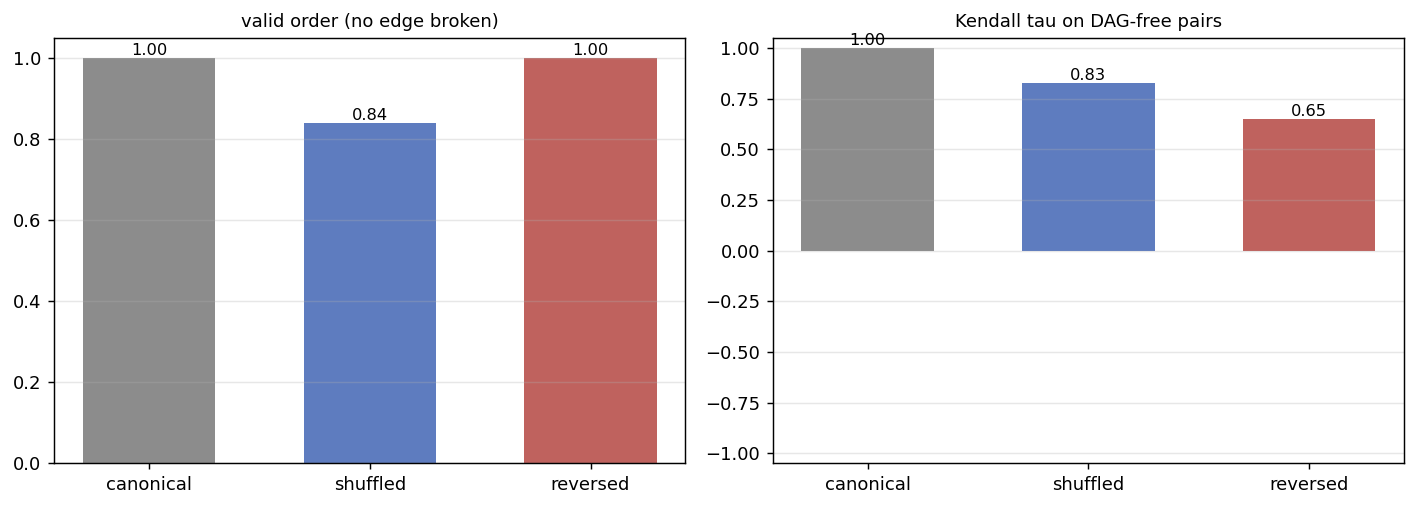

In [6]:
# ── §2 summary ─────────────────────────────────────────────────────────────
ok = beh_df[beh_df.complete]
t = Table(title=f"order under dependencies (N={len(beh_df)}, {len(ok)} emitted all steps)")
for c in ["listing mode", "n", "valid order", "mean #violations", "follows listing exactly",
          "tau on FREE pairs"]:
    t.add_column(c, justify="left" if c == "listing mode" else "right")
for mode in MODES:
    s = ok[ok["mode"] == mode]
    t.add_row(mode, str(len(s)), f"{s.valid.mean():.3f}", f"{s.n_violations.mean():.2f}",
              f"{s.follows_listing.mean():.3f}", f"{s.tau_free.mean():+.3f}")
rich_print(t)
rich_print("[grey58]`valid order` = no edge broken. `follows listing exactly` should be near 0 in "
           "the reversed mode IF the model reorders. `tau on FREE pairs` near +1 means the listing "
           "still governs wherever the DAG leaves a choice — the two are not in conflict.[/grey58]")

pg = Table(title="per graph (reversed listing only — where the DAG and the prompt disagree)")
for c in ["graph", "n", "valid", "#violations", "tau free", "incomplete"]:
    pg.add_column(c, justify="left" if c == "graph" else "right")
for g in GRAPHS:
    s = beh_df[(beh_df.graph == g.name) & (beh_df["mode"] == "reversed")]
    sc = s[s.complete]
    pg.add_row(g.name, str(len(s)),
               f"{sc.valid.mean():.2f}" if len(sc) else "—",
               f"{sc.n_violations.mean():.2f}" if len(sc) else "—",
               f"{sc.tau_free.mean():+.2f}" if len(sc) and not np.isnan(sc.tau_free.mean()) else "—",
               f"{1 - s.complete.mean():.2f}")
rich_print(pg)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=130)
for ax, (col, ttl, lim) in zip(axes, [("valid", "valid order (no edge broken)", (0, 1.05)),
                                      ("tau_free", "Kendall tau on DAG-free pairs", (-1.05, 1.05))]):
    ys = [ok[ok["mode"] == m][col].mean() for m in MODES]
    ax.bar(range(len(MODES)), ys, color=["#8c8c8c", "#5E7CBF", "#BF625E"], width=0.6)
    for x, y in zip(range(len(MODES)), ys):
        ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(MODES))); ax.set_xticklabels(MODES)
    ax.set_ylim(*lim); ax.set_title(ttl, fontsize=10); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

In [7]:
# ── §2 qualitative: one generation per graph, listing vs emitted ───────────
for g, params, listing, prompt, body, order, vio in examples:
    if g.name not in ("divs_diamond", "two_producers", "deep_chain"): continue
    rich_print(Panel(Text(prompt.split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()),
                     title=f"[bold]{g.name}[/bold] · instruction (listing order)",
                     title_align="left", border_style="grey42", padding=(0, 1)))
    rich_print(Panel(Text(body.strip(), style="sea_green3"), title="generated body",
                     title_align="left", border_style="grey42", padding=(0, 1)))
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left",
              title=f"listing  {' -> '.join(listing)}\nemitted  {' -> '.join(order)}")
    for c in ["valid order", "#violations", "broken edges", "tau on free pairs"]:
        t.add_column(c, justify="right")
    t.add_row(Text("YES" if not vio else "NO", style="green" if not vio else "red"),
              str(len(vio)), str(vio) if vio else "—", f"{free_pair_tau(g, listing, order):+.2f}")
    rich_print(t); rich_print("")

╭─ divs_diamond · instruction (listing order) ────────────────────────────────────────────────────────────────────╮
│ Write a Python program that implements a function `check_conditions` which, given an integer n, computes the    │
│ following:                                                                                                      │
│                                                                                                                 │
│ 1. `divs` = the list of all divisors of n, in ascending order                                                   │
│ 2. `many` = divs has more than 5 elements                                                                       │
│ 3. `big_last` = the last element of divs is greater than 39                                                     │
│ 4. `both` = many and big_last are both true                                                                     │
│                                                                                                                 │
│ For each item, in the order listed, assign the result to a local variable with exactly the name given. After    │
│ all items have been computed, use a SINGLE print statement that, using those variables, reports each value.     │
│ Compute everything inside `check_conditions`; do not define any helper functions.                               │
│ Do not include any comments in your code.                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ generated body ────────────────────────────────────────────────────────────────────────────────────────────────╮
│ divs = [i for i in range(1, n + 1) if n % i == 0]                                                               │
│     many = len(divs) > 5                                                                                        │
│     big_last = divs[-1] > 39                                                                                    │
│     both = many and big_last                                                                                    │
│     print(f"divs={divs}, many={many}, big_last={big_last}, both={both}")                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

listing  divs -> many -> big_last -> both                                                                          
emitted  divs -> many -> big_last -> both                                                                          
                                                                                                                   
             valid order               #violations                broken edges                   tau on free pairs 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
                     YES                         0                           —                               +1.00

╭─ divs_diamond · instruction (listing order) ────────────────────────────────────────────────────────────────────╮
│ Write a Python program that implements a function `check_conditions` which, given an integer n, computes the    │
│ following:                                                                                                      │
│                                                                                                                 │
│ 1. `divs` = the list of all divisors of n, in ascending order                                                   │
│ 2. `both` = many and big_last are both true                                                                     │
│ 3. `many` = divs has more than 4 elements                                                                       │
│ 4. `big_last` = the last element of divs is greater than 39                                                     │
│                                                                                                                 │
│ For each item, in the order listed, assign the result to a local variable with exactly the name given. After    │
│ all items have been computed, use a SINGLE print statement that, using those variables, reports each value.     │
│ Compute everything inside `check_conditions`; do not define any helper functions.                               │
│ Do not include any comments in your code.                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ generated body ────────────────────────────────────────────────────────────────────────────────────────────────╮
│ divs = [i for i in range(1, n + 1) if n % i == 0]                                                               │
│     many = len(divs) > 4                                                                                        │
│     big_last = divs[-1] > 39                                                                                    │
│     both = many and big_last                                                                                    │
│     print(f"divs = {divs}, both = {both}, many = {many}, big_last = {big_last}")                                │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

listing  divs -> both -> many -> big_last                                                                          
emitted  divs -> many -> big_last -> both                                                                          
                                                                                                                   
             valid order               #violations                broken edges                   tau on free pairs 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
                     YES                         0                           —                               +1.00

... (17 outputs left out)

listing  sq_big -> dsum -> digits -> dsum_sq                                                                       
emitted  digits -> dsum -> dsum_sq -> sq_big                                                                       
                                                                                                                   
             valid order               #violations                broken edges                   tau on free pairs 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
                     YES                         0                           —                                +nan

╭─ deep_chain · instruction (listing order) ──────────────────────────────────────────────────────────────────────╮
│ Write a Python program that implements a function `check_conditions` which, given an integer n, computes the    │
│ following:                                                                                                      │
│                                                                                                                 │
│ 1. `sq_big` = dsum_sq is greater than 20                                                                        │
│ 2. `dsum_sq` = dsum multiplied by itself                                                                        │
│ 3. `dsum` = the sum of the elements of digits                                                                   │
│ 4. `digits` = the list of n's decimal digits, most significant first                                            │
│                                                                                                                 │
│ For each item, in the order listed, assign the result to a local variable with exactly the name given. After    │
│ all items have been computed, use a SINGLE print statement that, using those variables, reports each value.     │
│ Compute everything inside `check_conditions`; do not define any helper functions.                               │
│ Do not include any comments in your code.                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ generated body ────────────────────────────────────────────────────────────────────────────────────────────────╮
│ digits = [int(d) for d in str(n)]                                                                               │
│     dsum = sum(digits)                                                                                          │
│     dsum_sq = dsum * dsum                                                                                       │
│     sq_big = dsum_sq > 20                                                                                       │
│     print(sq_big, dsum_sq, dsum, digits)                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

listing  sq_big -> dsum_sq -> dsum -> digits                                                                       
emitted  digits -> dsum -> dsum_sq -> sq_big                                                                       
                                                                                                                   
             valid order               #violations                broken edges                   tau on free pairs 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
                     YES                         0                           —                                +nan

## 3. Causal — does move-on still fire when the next step's dependency is unmet?

`16` established that one aggregate move-on vector advances the model at the pivot with rate ~1.0
when the steps are independent. Here the next step may **need something that is not ready yet**.

Two readings, sharply different predictions:

* pure `next()` — content-agnostic, so it advances regardless, and the model happily writes code
  against a value that is not finished;
* dependency-gated — the flip rate drops when the target is not yet satisfiable.

### Three levels of "unmet", and why the comparison is within-graph

The pivot is a step written as an *incomplete multi-line* implementation, so a step depending on the
pivot has its variable **bound but wrong** (`total = 0` is already on the page) rather than
undefined. That is weaker than a `NameError`, so the levels are separated:

| level | the target's producer is | example |
|---|---|---|
| **MET** | complete above the pivot | `mixed_dep`: pivot mid-`total`, next `many` (needs `divs`, done) |
| **PARTIAL** | the pivot itself — bound but unfinished | `mixed_dep`: next `abundant` (needs `total`) |
| **ABSENT** | not written anywhere yet — a real `NameError` | `two_producers`: pivot mid-`divs`, next `all_even` (needs `digits`) |

Each pair is compared **within one graph**, with the same prefill, the same pivot, the same params —
only which step the listing puts next changes. Across-graph comparisons would confound the level
with the content.

In [8]:
# ── §3: move-on under met / partial / absent dependencies ──────────────────
from src.goals.head_loc_attn import HeadMask, forward_with_src_replacement, get_o_proj_inputs_batch
from src.goals.completion_pairs import build_completion_pairs
from src.goals.goalscope import headpatched_generate
from src.goals.oid_gaze import cache_root
from src.tokens import prepare_input

# decision heads + move-on vector — same config as 16 §1, so the numbers are comparable
VERSION, TAG, SEL_THR = "conditions", "lam10.0", 0.8
_root = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
_c = [t for t in os.listdir(_root) if os.path.isdir(os.path.join(_root, t)) and TAG in t]
DCK = torch.load(os.path.join(_root, max(_c, key=lambda t: os.path.getmtime(os.path.join(_root, t))),
                              "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in DCK["layers"]]
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(DCK["mask_values"].numpy() > SEL_THR)]
PATCH_POS = int(DCK["patch_tokens"][0]) if len(DCK.get("patch_tokens", [-2])) == 1 else -2
ALPHA = 2.0

def get_mask_bin(heads):
    hm = HeadMask(mt.n_layer, mt.model.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads: hm.values[l, h] = 1.0
    return hm
DEC_MASK, NULL_MASK = get_mask_bin(decision_heads), get_mask_bin([])

_pairs = build_completion_pairs(mt, n_pairs=256, target_slots=(1, 2, 3), direction="sl->ml",
                                same=True, patch_tokens=(PATCH_POS,), seed=1234, log=logger.debug)
_acc = {l: [] for l in dec_layers}
for i in range(0, len(_pairs), 16):
    ch = [p.source.sl_prompt for p in _pairs[i:i + 16]]
    cache = get_o_proj_inputs_batch(mt, ch, dec_layers, token_positions=[PATCH_POS])
    for l in dec_layers: _acc[l].append(cache[l][:, 0, :].float().cpu())
MEAN_SRC = torch.stack([torch.cat(_acc[l], 0).mean(0) for l in dec_layers])
print(f"decision heads {len(decision_heads)} · PATCH_POS={PATCH_POS} · move-on vector {tuple(MEAN_SRC.shape)}")

@torch.no_grad()
def probe_next(prompt, names, patched):
    """(kway argmax name, greedily emitted name) at the pivot."""
    dev = next(mt._model.parameters()).device
    pid = mt.tokenizer(prompt, add_special_tokens=False)["input_ids"]; P = len(pid)
    pivot_abs = P + PATCH_POS                       # absolute: survives appending a continuation
    conts = [mt.tokenizer(prompt + f" {n}", add_special_tokens=False)["input_ids"][P:] for n in names]
    L = max(len(c) for c in conts)
    ids = torch.full((len(names), P + L), mt.tokenizer.pad_token_id or 0, dtype=torch.long)
    att = torch.zeros_like(ids)
    for i, c in enumerate(conts):
        ids[i, :P] = torch.tensor(pid); ids[i, P:P + len(c)] = torch.tensor(c); att[i, :P + len(c)] = 1
    inp = {"input_ids": ids.to(dev), "attention_mask": att.to(dev)}
    if not patched:
        logits = mt._model(**inp).logits.float()
    else:
        from src.goals.head_loc_attn import src_replacement_hooks
        src_b = MEAN_SRC.unsqueeze(0).expand(len(names), -1, -1).contiguous()
        with src_replacement_hooks(mt, src_b, DEC_MASK, dec_layers, ALPHA, [pivot_abs]):
            logits = mt._model(**inp).logits.float()
    lp = torch.log_softmax(logits, -1)
    sc = [float(lp[i, torch.arange(P - 1, P - 1 + len(c), device=dev),
                    torch.tensor(c, device=dev)].mean()) for i, c in enumerate(conts)]
    one = prepare_input(prompts=prompt, tokenizer=mt)
    gen = headpatched_generate(mt, dict(one), MEAN_SRC, DEC_MASK if patched else NULL_MASK,
                               dec_layers, max_new_tokens=14, n_steer_tokens=1,
                               patch_input_positions=[PATCH_POS], alpha=ALPHA)
    m = re.match(r"\s*([A-Za-z_][A-Za-z0-9_]*)", gen.split("\n")[0])
    return names[int(np.argmax(sc))], (m.group(1) if m else None), gen

# within-graph minimal pairs: same prefill, same pivot, only the NEXT step changes
CONFIGS = [
    dict(graph="mixed_dep",     prefill=("divs",),  pivot="total",
         arms={"MET": "many", "PARTIAL": "abundant"}),
    dict(graph="two_producers", prefill=(),         pivot="divs",
         arms={"PARTIAL": "many", "ABSENT": "all_even"}),
]
N_CAUSAL = 48

rows, shown = [], set()
for cfg in CONFIGS:
    g = GRAPHS_BY_NAME[cfg["graph"]]
    rest_pool = [v for v in g.vars if v not in cfg["prefill"] and v != cfg["pivot"]]
    for level, nxt in cfg["arms"].items():
        for r in tqdm(range(N_CAUSAL), desc=f"{g.name}/{level}", leave=False):
            rng = random.Random(hash((g.name, level, r)) % (2**31))
            params = g.sample_params(rng)
            tail = [nxt] + [v for v in rest_pool if v != nxt]
            listing = list(cfg["prefill"]) + [cfg["pivot"]] + tail
            prompt = replace_in_code_newline_with_tabnewline(
                build_dep_prompt(g, params, listing, prefill_vars=cfg["prefill"],
                                 pivot_var=cfg["pivot"])) + "   "
            for arm in (False, True):
                kw, emit, gen = probe_next(prompt, g.vars, patched=arm)
                rows.append(dict(graph=g.name, level=level, rep=r, arm="decision" if arm else "clean",
                                 target=nxt, pivot=cfg["pivot"],
                                 kway_moved=kw == nxt, emit_moved=emit == nxt,
                                 emit_pivot=emit == cfg["pivot"], emitted=emit))
                if arm and (g.name, level) not in shown:
                    shown.add((g.name, level))
                    rows[-1]["demo"] = (listing, prompt, gen)

cau_df = pd.DataFrame(rows)
print(f"{len(cau_df)} rows = {sum(len(c['arms']) for c in CONFIGS)} cells x {N_CAUSAL} reps x 2 arms")

decision heads 181 · PATCH_POS=-2 · move-on vector (64, 5120)


mixed_dep/MET:   0%|          | 0/48 [00:00<?, ?it/s]

mixed_dep/PARTIAL:   0%|          | 0/48 [00:00<?, ?it/s]

two_producers/PARTIAL:   0%|          | 0/48 [00:00<?, ?it/s]

two_producers/ABSENT:   0%|          | 0/48 [00:00<?, ?it/s]

384 rows = 4 cells x 48 reps x 2 arms


                     move-on under unmet dependencies (alpha=2.0, N=48 per cell)                     
┏━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ graph         ┃ level   ┃ target   ┃ arm      ┃ kway move-on ┃ emitted = target ┃ emitted = pivot ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mixed_dep     │ MET     │ many     │ clean    │        0.000 │            0.000 │           0.000 │
│               │         │          │ decision │        1.000 │            0.000 │           0.000 │
│               │ PARTIAL │ abundant │ clean    │        0.000 │            0.000 │           0.000 │
│               │         │          │ decision │        1.000 │            0.000 │           0.000 │
│ two_producers │ PARTIAL │ many     │ clean    │        0.000 │            0.000 │           0.000 │
│               │         │          │ decision │        1.000 │            0.000 │           0.000 │
│               │ ABSENT  │ all_even │ clean    │        1.000 │            0.000 │           0.000 │
│               │         │          │ decision │        1.000 │            0.000 │           0.000 │
└───────────────┴─────────┴──────────┴──────────┴──────────────┴──────────────────┴─────────────────┘

Compare levels WITHIN a graph. A pure next() predicts the decision arm is flat across MET / PARTIAL / ABSENT — it 
advances regardless and writes against a value that is not ready. A dependency-gated signal predicts a drop as the 
level worsens.

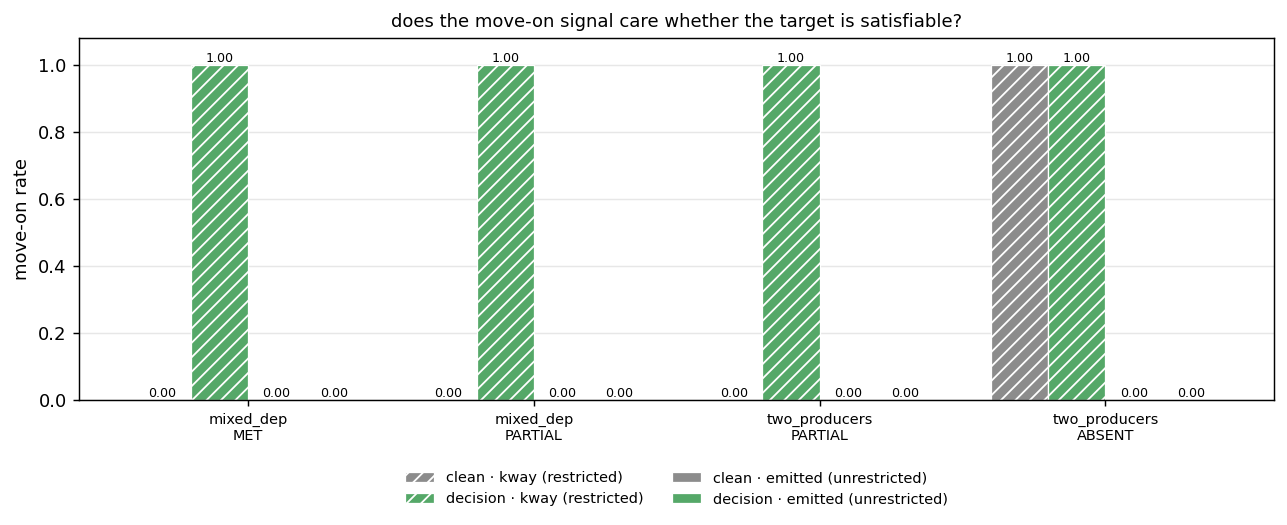

╭─ mixed_dep · MET · listing divs -> total -> many -> abundant · pivot total · target many ───────────────────────╮
│ def check_conditions(n: int):                                                                                   │
│     divs = [d for d in range(1, abs(n) + 1) if n % d == 0]                                                      │
│     total = 0                                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ patched (move-on injected) ────────────────────────────────────────────────────────────────────────────────────╮
│ for d in divs:                                                                                                  │
│         total += d                                                                                              │
│     many                                                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ mixed_dep · PARTIAL · listing divs -> total -> abundant -> many · pivot total · target abundant ───────────────╮
│ def check_conditions(n: int):                                                                                   │
│     divs = [d for d in range(1, abs(n) + 1) if n % d == 0]                                                      │
│     total = 0                                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ patched (move-on injected) ────────────────────────────────────────────────────────────────────────────────────╮
│ for d in divs:                                                                                                  │
│         total += d                                                                                              │
│     abundant                                                                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ two_producers · PARTIAL · listing divs -> many -> digits -> all_even -> both · pivot divs · target many ───────╮
│ def check_conditions(n: int):                                                                                   │
│     divs = []                                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ patched (move-on injected) ────────────────────────────────────────────────────────────────────────────────────╮
│ for i in range(1, n + 1):                                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ two_producers · ABSENT · listing divs -> all_even -> digits -> many -> both · pivot divs · target all_even ────╮
│ def check_conditions(n: int):                                                                                   │
│     divs = []                                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ patched (move-on injected) ────────────────────────────────────────────────────────────────────────────────────╮
│ for i in range(1, n + 1):                                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

: 

In [ ]:
# ── §3 summary — flip rate by dependency level, within graph ───────────────
t = Table(title=f"move-on under unmet dependencies (alpha={ALPHA}, N={N_CAUSAL} per cell)")
for c in ["graph", "level", "target", "arm", "kway move-on", "emitted = target", "emitted = pivot"]:
    t.add_column(c, justify="left" if c in ("graph", "level", "target", "arm") else "right")
for cfg in CONFIGS:
    for level in cfg["arms"]:
        sub = cau_df[(cau_df.graph == cfg["graph"]) & (cau_df.level == level)]
        for arm in ("clean", "decision"):
            g_ = sub[sub.arm == arm]
            sty = {"MET": "green", "PARTIAL": "yellow", "ABSENT": "red"}[level]
            t.add_row(cfg["graph"] if (arm == "clean" and level == list(cfg["arms"])[0]) else "",
                      Text(level, style=sty) if arm == "clean" else "",
                      g_.target.iloc[0] if arm == "clean" else "", arm,
                      f"{g_.kway_moved.mean():.3f}", f"{g_.emit_moved.mean():.3f}",
                      f"{g_.emit_pivot.mean():.3f}")
rich_print(t)
rich_print("[grey58]Compare levels WITHIN a graph. A pure next() predicts the decision arm is flat "
           "across MET / PARTIAL / ABSENT — it advances regardless and writes against a value that "
           "is not ready. A dependency-gated signal predicts a drop as the level worsens.[/grey58]")

# colour = arm, hatch = metric: `kway` (restricted argmax over the graph's variable names) is
# striped; `emitted` (what the model actually wrote, unrestricted) is solid.
ARMC = {"clean": "#8c8c8c", "decision": "#55a868"}
BARS = [("clean", "kway_moved"), ("decision", "kway_moved"),
        ("clean", "emit_moved"), ("decision", "emit_moved")]
cells = [(c_["graph"], lv) for c_ in CONFIGS for lv in c_["arms"]]
fig, ax = plt.subplots(figsize=(10, 4.6), dpi=130)
xs = np.arange(len(cells)); w = 0.2
for k, (arm, met) in enumerate(BARS):
    kway = met.startswith("kway")
    ys = [cau_df[(cau_df.graph == gr) & (cau_df.level == lv) & (cau_df.arm == arm)][met].mean()
          for gr, lv in cells]
    ax.bar(xs + k * w - 1.5 * w, ys, w, color=ARMC[arm],
           hatch="///" if kway else None, edgecolor="white", linewidth=0.7,
           label=f"{arm} · {'kway (restricted)' if kway else 'emitted (unrestricted)'}")
    for x, y in zip(xs + k * w - 1.5 * w, ys):
        ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels([f"{g_}\n{lv}" for g_, lv in cells], fontsize=8)
ax.set_ylabel("move-on rate"); ax.set_ylim(0, 1.08)
ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
ax.set_title("does the move-on signal care whether the target is satisfiable?", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, fontsize=8)
plt.tight_layout(); fig.subplots_adjust(bottom=0.32); plt.show()

# one patched generation per cell, to read what it actually wrote
for _, r in cau_df[cau_df.get("demo").notna()].iterrows() if "demo" in cau_df else []:
    listing, prompt, gen = r["demo"]
    rich_print(Panel(Text(prompt.split("<code>")[-1].strip()),
                     title=f"[bold]{r['graph']} · {r['level']}[/bold] · listing "
                           f"{' -> '.join(listing)} · pivot {r['pivot']} · target {r['target']}",
                     title_align="left", border_style="grey42", padding=(0, 1)))
    rich_print(Panel(Text(gen.strip(), style="salmon1"), title="patched (move-on injected)",
                     title_align="left", border_style="salmon1", padding=(0, 1)))
    rich_print("")